# YOLOv8 Inference and Prediction JSON Generation

In this notebook, I will perform inference using the trained YOLOv8 model on the test dataset.

For every test image, the model predictions will be converted into our custom JSON format:

```json
{
    "image_id": "image_001",
    "image_path": "path/to/image.jpg",
    "image_width": 1920,
    "image_height": 1080,
    "predictions": [
        {
            "class_id": 0,
            "confidence": 0.92,
            "bbox": [100, 200, 300, 400]
        }
    ]
}
```

The bounding boxes are stored in **XYXY format**:

```text
[x1, y1, x2, y2]
```

The generated prediction JSON files will later be used by `ImageEvaluator` and `DatasetEvaluator` to evaluate the YOLOv8 model.

## Workflow

1. Load the trained YOLOv8 model.
2. Run inference on test images.
3. Extract predicted bounding boxes, class IDs, and confidence scores.
4. Convert predictions into the custom JSON format.
5. Save one prediction JSON file for every test image.


## Imports and git clone

In [1]:
!git clone https://github.com/gracyy-rm/Road_damage_object_detection.git

Cloning into 'Road_damage_object_detection'...
remote: Enumerating objects: 68, done.
remote: Counting objects: 100% (68/68), done.
remote: Compressing objects: 100% (51/51), done.
remote: Total 68 (delta 28), reused 54 (delta 14), pack-reused 0 (from 0)
Receiving objects: 100% (68/68), 9.13 MiB | 24.72 MiB/s, done.
Resolving deltas: 100% (28/28), done.


In [2]:
%cd /kaggle/working/Road_damage_object_detection

/kaggle/working/Road_damage_object_detection


In [3]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.7 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 5.6 MB/s eta 0:00:00


In [4]:
from pathlib import Path
from src.inference import YOLOInference
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [5]:
!pwd

/kaggle/working/Road_damage_object_detection


## YOLOv8-s Inference 

In [6]:
model_path_yolov8s = "/kaggle/input/datasets/gracyyadav79/yolo-model/Road_damage_object_detection/outputs/yolov8s_50epochs/weights/best.pt"

PROJECT_DIR = Path("/kaggle/working/road_damage_detection")

test_images_dir= Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images")

pred_json_dir = Path("/kaggle/working/predictions/yolo")
pred_json_dir.mkdir(parents=True, exist_ok=True)

## Inference object 

In [9]:
inference_yolo_s = YOLOInference(model_path=model_path_yolov8s)

## Inference on single image

In [10]:
sample_json_dir = Path("/kaggle/working/sample_pred")
sample_json_dir.mkdir(parents=True, exist_ok=True)

In [11]:
image_path1 = "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images/China_Drone_000383.jpg"
output_path1= sample_json_dir/"china.json"

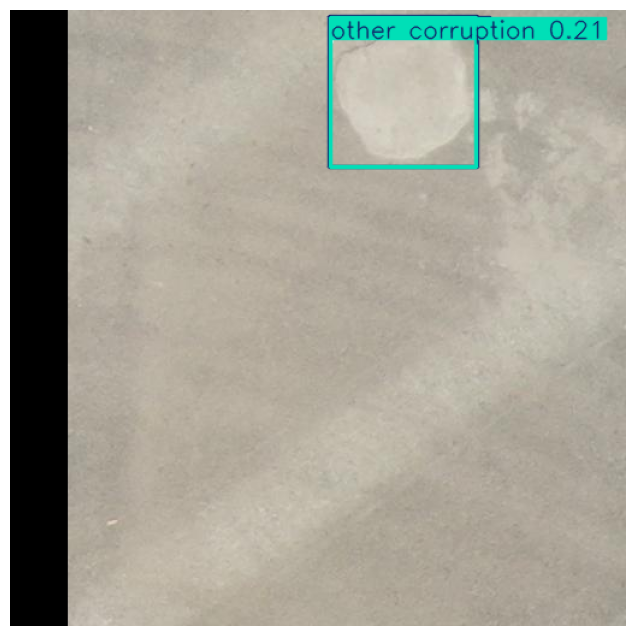

{'image_id': 'China_Drone_000383',
 'image_path': '/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images/China_Drone_000383.jpg',
 'image_width': 512,
 'image_height': 512,
 'predictions': [{'class_id': 3,
   'label': 'other corruption',
   'confidence': 0.2134,
   'bbox': [266.55, 6.75, 387.91, 130.21]},
  {'class_id': 4,
   'label': 'pothole',
   'confidence': 0.1625,
   'bbox': [265.32, 5.83, 388.33, 130.02]}]}

In [13]:
result = inference_yolo_s.predict_image(
    image_path=image_path1,
    output_path=output_path1,
    visualize=True
)
result

In [11]:
import json

with open(output_path1,"r") as file:
    saved_prediction = json.load(file)
saved_prediction

In [14]:
inference_yolo_s.predict_dataset(
    images_dir=test_images_dir,
    output_dir=pred_json_dir,
)

Processing images:   0%|          | 0/5758 [00:00<?, ?it/s]

Generated 5758 prediction JSON files in: /kaggle/working/predictions/yolo


In [15]:
import shutil
from pathlib import Path

pred_json_dir = Path("/kaggle/working/predictions/yolo")

shutil.make_archive(
    "/kaggle/working/yolo_predictions",
    "zip",
    root_dir=pred_json_dir.parent,
    base_dir=pred_json_dir.name
)

'/kaggle/working/yolo_predictions.zip'

## YOLOv8-L Inference 

In [17]:
model_path_yolov8L = "/kaggle/input/models/gracyyadav79/yolov8-l/pytorch/default/1/best.pt"

PROJECT_DIR = Path("/kaggle/working/road_damage_detection")

test_images_dir= Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images")

pred_json_dir = Path("/kaggle/working/predictions/yolo_L")
pred_json_dir.mkdir(parents=True, exist_ok=True)

In [18]:
inference_yolo_L = YOLOInference(model_path=model_path_yolov8L)

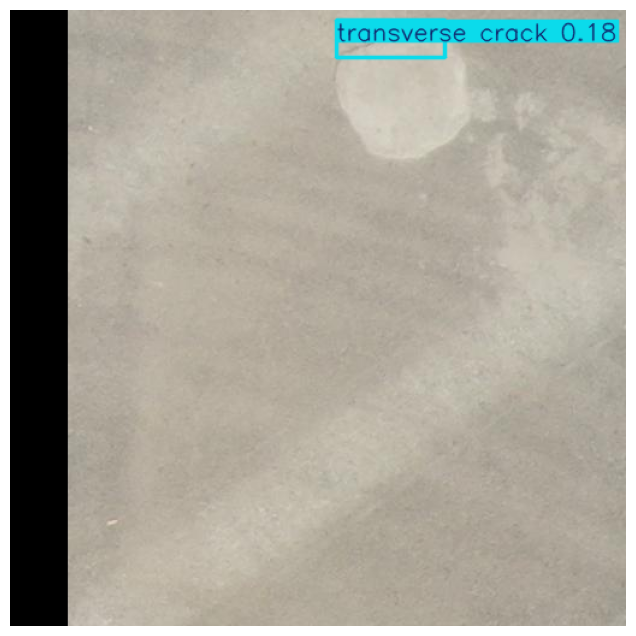

{'image_id': 'China_Drone_000383',
 'image_path': '/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images/China_Drone_000383.jpg',
 'image_width': 512,
 'image_height': 512,
 'predictions': [{'class_id': 1,
   'label': 'transverse crack',
   'confidence': 0.1759,
   'bbox': [271.93, 8.18, 361.98, 39.08]}]}

In [20]:
image_path1 = "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images/China_Drone_000383.jpg"
result = inference_yolo_L.predict_image(image_path=image_path1,visualize=True)
result

In [21]:
inference_yolo_L.predict_dataset(
    images_dir=test_images_dir,
    output_dir=pred_json_dir,
)

Processing images:   0%|          | 0/5758 [00:00<?, ?it/s]

Generated 5758 prediction JSON files in: /kaggle/working/predictions/yolo_L


In [22]:
import shutil
from pathlib import Path

pred_json_dir = Path("/kaggle/working/predictions/yolo_L")

shutil.make_archive(
    "/kaggle/working/yolov8_L",
    "zip",
    root_dir=pred_json_dir.parent,
    base_dir=pred_json_dir.name
)

'/kaggle/working/yolov8_L.zip'

## RTDETR-L Inference 

In [23]:
model_path_rtdetrL = "/kaggle/input/datasets/gracyyadav79/rtdetr-l/best.pt"

PROJECT_DIR = Path("/kaggle/working/road_damage_detection")

test_images_dir= Path("/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images")

pred_json_dir = Path("/kaggle/working/predictions/rtdetr_L")
pred_json_dir.mkdir(parents=True, exist_ok=True)

In [24]:
inference_rtdetrL = YOLOInference(model_path=model_path_rtdetrL)

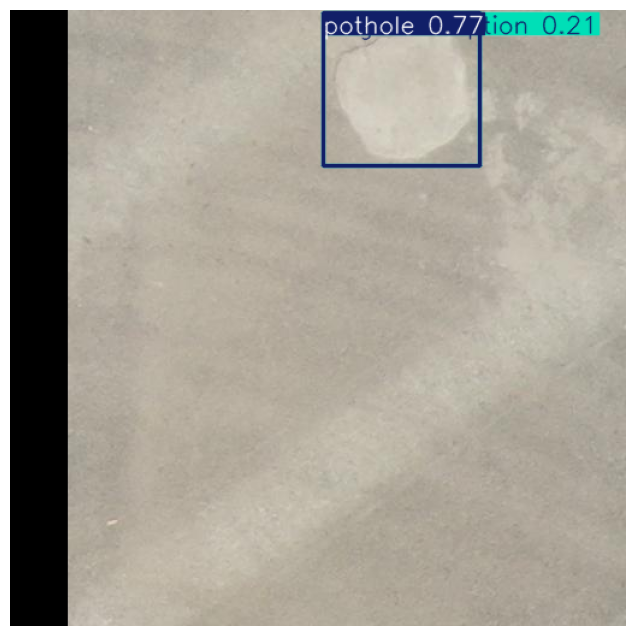

{'image_id': 'China_Drone_000383',
 'image_path': '/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images/China_Drone_000383.jpg',
 'image_width': 512,
 'image_height': 512,
 'predictions': [{'class_id': 4,
   'label': 'pothole',
   'confidence': 0.7665,
   'bbox': [260.87, 2.41, 390.99, 129.49]},
  {'class_id': 3,
   'label': 'other corruption',
   'confidence': 0.2124,
   'bbox': [260.87, 2.41, 390.99, 129.49]},
  {'class_id': 2,
   'label': 'alligator crack',
   'confidence': 0.1442,
   'bbox': [260.87, 2.41, 390.99, 129.49]}]}

In [26]:
image_path1 = "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images/China_Drone_000383.jpg"
result = inference_rtdetrL.predict_image(image_path=image_path1,visualize=True)
result

In [27]:
inference_rtdetrL.predict_dataset(
    images_dir=test_images_dir,
    output_dir=pred_json_dir,
)

Processing images:   0%|          | 0/5758 [00:00<?, ?it/s]

Generated 5758 prediction JSON files in: /kaggle/working/predictions/rtdetr_L


In [29]:
import shutil
from pathlib import Path

pred_json_dir = Path("/kaggle/working/predictions/rtdetr_L")

shutil.make_archive(
    "/kaggle/working/rtdetr_L",
    "zip",
    root_dir=pred_json_dir.parent,
    base_dir=pred_json_dir.name
)

'/kaggle/working/rtdetr_L.zip'